# 🐧 Assignment: Support Vector Machines in Practice
### Classifying Palmer Penguins & Tuning the Soft-Margin Knob **C**

**CS535 / EE514 — Machine Learning**  ·  Companion lab to the SVM lecture

---

In the lecture you built the intuition for SVMs by hand — the *widest street*, the
*support vectors* that hold it up, and the soft-margin dial **C** that trades a little
training accuracy for a wider, more robust margin. In this lab you will see all of that
come alive on **real data**, using scikit-learn's ready-made `SVC` classifier.

You will not implement the optimizer yourself — that is what the library is for. Your job
is to **apply** SVMs correctly, **visualize** what they do, and above all **investigate how
the parameter `C` changes the decision boundary**, the number of support vectors, and the
balance between underfitting and overfitting.

### Learning objectives
By the end you should be able to:
1. Load, explore, and **preprocess** a real dataset for an SVM (including *why feature scaling is essential*).
2. Train a linear SVM with `sklearn.svm.SVC` and read off its accuracy and support vectors.
3. **Visualize** the decision boundary, the margin, and the support vectors.
4. **Sweep the regularization parameter `C`** and explain its effect in terms of margin width, support-vector count, and the **bias–variance tradeoff**.
5. (Stretch) Use an **RBF kernel** and **`GridSearchCV`** to select hyper-parameters.


## Before you start

- **Allowed libraries:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`. Nothing else is needed.
- **Data file:** `penguins.csv` must sit in the **same folder** as this notebook.
- **How to work:** fill in every cell marked `# TODO`. Replace each `...` / `raise NotImplementedError`
  with your own code. Run the notebook **top to bottom** (Kernel ▸ Restart & Run All) before submitting —
  it must run with no errors.
- **Write-up:** some cells ask for a short written answer. Put it in the **markdown** cell provided.
- **Estimated time:** 2–3 hours (Parts 0–6). Parts 7–8 are optional stretch goals.

### A 30-second refresher from the lecture
| Term | Meaning |
|---|---|
| **Margin** | Distance from the boundary to the nearest point. SVMs make it as wide as possible. |
| **Support vectors** | The handful of points that touch the margin and *define* the boundary. |
| **Soft margin / `C`** | `C` is the penalty for points that violate the margin. **Large C** → strict, narrow street (low bias, high variance). **Small C** → lenient, wide street (high bias, low variance). |
| **Kernel** | A trick to bend the boundary for data a straight line can't separate (`kernel='rbf'`). |

> 🎯 **The one big idea of this lab:** *how does turning the `C` knob reshape the SVM?*


---
## Part 0 — Setup

Run the next cell to import everything and load the data. (Nothing to edit here.)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV

plt.rcParams["figure.dpi"] = 110
penguins = pd.read_csv("penguins.csv")
print("Loaded", penguins.shape[0], "penguins with columns:")
print(list(penguins.columns))
penguins.head()

Loaded 344 penguins with columns:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


The dataset records **344 penguins** from three species living in the **Palmer Archipelago,
Antarctica**, collected by Dr. Kristen Gorman. Each row is one penguin, with body measurements:

| Feature | Meaning |
|---|---|
| `bill_length_mm` | length of the bill (beak) |
| `bill_depth_mm` | depth (thickness) of the bill |
| `flipper_length_mm` | flipper length |
| `body_mass_g` | body mass in grams |
| `species` | **Adelie**, **Chinstrap**, or **Gentoo** ← what we want to predict |

<img src="https://allisonhorst.github.io/palmerpenguins/reference/figures/lter_penguins.png" width="0" alt=""/>


---
## Part 1 — Meet the data (exploration)

Before modelling, always *look* at your data. Run the cell below to see how the three
species separate across two bill measurements.

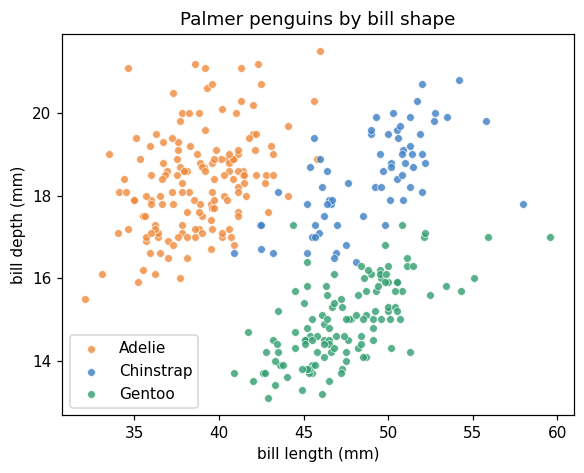

In [3]:
df = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm",
                             "flipper_length_mm", "body_mass_g"]).copy()

fig, ax = plt.subplots(figsize=(6, 4.5))
for sp, color in zip(["Adelie", "Chinstrap", "Gentoo"],
                     ["#ef8a3b", "#3b7fc4", "#2f9e6f"]):
    d = df[df.species == sp]
    ax.scatter(d.bill_length_mm, d.bill_depth_mm, s=26, alpha=0.8,
               label=sp, edgecolors="w", linewidths=0.5, c=color)
ax.set_xlabel("bill length (mm)"); ax.set_ylabel("bill depth (mm)")
ax.legend(); ax.set_title("Palmer penguins by bill shape")
plt.show()

**Q1 (written).** Look at the scatter plot. Which species looks **easiest** to separate from
the others with a straight line, and which **two** species overlap the most? We will deliberately
pick the harder pair so that the value of `C` actually matters.

*Your answer:*  ✍️ **Gentoo** is the easiest to separate: its bills are clearly less deep (about 14–17 mm) than the other two species, so it forms its own cluster and one straight line cuts it off. **Adelie and Chinstrap overlap the most** — both have similar bill depths (~17–20 mm), and they differ mainly in bill length (Chinstrap bills are longer), so their clouds touch in the middle. That is the pair we use.

---
## Part 2 — Frame the problem

To **see** the decision boundary we need a 2-D problem, so we will use just **two features**
(`bill_length_mm`, `bill_depth_mm`) and the **two overlapping species**: **Adelie vs Chinstrap**.

Fill in the TODO to build:
- `X` — an `(n, 2)` array of the two bill features, and
- `y` — labels where **Adelie = 0** and **Chinstrap = 1**.

In [4]:
pair = df[df.species.isin(["Adelie", "Chinstrap"])].copy()
FEATURES = ["bill_length_mm", "bill_depth_mm"]

# TODO: build X (the two FEATURES as a NumPy array) and y (Adelie=0, Chinstrap=1).
X = pair[FEATURES].values         # hint: pair[FEATURES].values
y = (pair["species"] == "Chinstrap").astype(int).values       # hint: (pair["species"] == "Chinstrap").astype(int).values

print("X shape:", X.shape, " | class counts:", np.bincount(y),
      "(Adelie, Chinstrap)")

X shape: (219, 2)  | class counts: [151  68] (Adelie, Chinstrap)


---
## Part 3 — Split and **scale** (don't skip this!)

SVMs measure **distances**, so a feature with a big numeric range would dominate one with a
small range. `bill_length` (~32–60) spans a wider range than `bill_depth` (~13–21), so we must
put them on the **same scale** with `StandardScaler` (mean 0, standard deviation 1).

**Golden rule:** fit the scaler on the **training set only**, then apply it to both train and test.
Fitting it on the test set too would leak information.

Fill in the TODOs.

In [5]:
# TODO 1: split into train/test (30% test, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

# TODO 2: fit StandardScaler on X_train ONLY, then transform both sets
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print("train:", X_train_s.shape[0], " test:", X_test_s.shape[0])

train: 153  test: 66


**Mini-experiment (given).** To see scaling bite, this demo uses two features with *very
different ranges*: `bill_length_mm` (tens) and `body_mass_g` (thousands). Body mass barely differs
between these two species, yet its huge numeric range lets it **dominate the distance** and drown
out the bill-length signal — until we scale. Run it and compare.

In [6]:
# Two features on very different scales: bill_length (~tens) vs body_mass (~thousands)
X_demo = pair[["bill_length_mm", "body_mass_g"]].values
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(
    X_demo, y, test_size=0.30, random_state=42, stratify=y)
scaler_demo = StandardScaler().fit(Xd_tr)

for label, A, B in [("WITHOUT scaling", Xd_tr, Xd_te),
                    ("WITH scaling", scaler_demo.transform(Xd_tr), scaler_demo.transform(Xd_te))]:
    m = SVC(kernel="linear", C=1).fit(A, yd_tr)
    print(f"{label:16s}  test accuracy = {m.score(B, yd_te):.3f}")

WITHOUT scaling   test accuracy = 0.970
WITH scaling      test accuracy = 1.000


**Q2 (written).** Did scaling change the result here? Explain in one or two sentences *why*
SVMs are sensitive to feature scales (think about what the margin is measured in).

*Your answer:* ✍️Yes: test accuracy went from **0.970 without scaling to 1.000 with scaling**. The SVM margin is a geometric distance, so it is measured in the units of the features. Body mass (thousands of grams) has a far bigger numeric range than bill length (tens of mm), so it dominates the distance and the margin, even though it barely differs between the two species and the useful bill-length signal gets drowned out. Standardizing puts every feature on the same scale so each contributes fairly.

---
## Part 4 — Train your first SVM and look at it

Run the given helper cell (the plotting function), then fill in the TODO to train a **linear SVM
with `C = 1`** and visualize it.

In [7]:
# === GIVEN: plotting helper — you do NOT need to edit this ===
import numpy as np
import matplotlib.pyplot as plt

ADELIE_C, CHINSTRAP_C = "#ef8a3b", "#3b7fc4"

def plot_svm_boundary(model, X, y, ax=None, title=None, show_margins=True):
    """Draw an SVM's decision regions, the margin street (decision_function = +/-1),
    the data points, and circle the support vectors. X must be the SAME (scaled)
    data the model was trained on, with exactly 2 columns."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5.2, 4.2))
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400),
                         np.linspace(y_min, y_max, 400))
    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, alpha=0.10, cmap="coolwarm")
    if show_margins:
        ax.contour(xx, yy, Z, levels=[-1, 0, 1],
                   colors=["#999", "black", "#999"],
                   linestyles=["--", "-", "--"], linewidths=[1, 1.6, 1])
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c=ADELIE_C, s=26,
               edgecolors="w", linewidths=0.6, label="Adelie")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c=CHINSTRAP_C, s=26,
               edgecolors="w", linewidths=0.6, label="Chinstrap")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=130, facecolors="none",
               edgecolors="black", linewidths=1.3, label="support vectors")
    ax.set_xlabel("bill length (standardized)")
    ax.set_ylabel("bill depth (standardized)")
    if title:
        ax.set_title(title, fontsize=11)
    return ax


train accuracy: 0.974
test  accuracy: 0.97
number of support vectors: 19


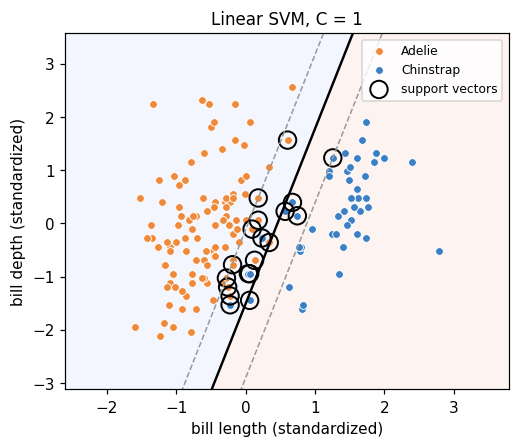

In [8]:
# TODO: train a linear SVM with C=1 on the SCALED training data.
svm = SVC(kernel="linear", C=1).fit(X_train_s, y_train)

print("train accuracy:", round(svm.score(X_train_s, y_train), 3))
print("test  accuracy:", round(svm.score(X_test_s, y_test), 3))
print("number of support vectors:", svm.support_vectors_.shape[0])

# Visualize it (uses the helper above):
plot_svm_boundary(svm, X_train_s, y_train, title="Linear SVM, C = 1")
plt.legend(loc="upper right", fontsize=8); plt.show()

**Q3 (written).** In the plot, the solid line is the boundary and the dashed lines are the
edges of the margin (the "street"). The circled points are the **support vectors**. In your own
words, what would happen to the boundary if you *moved a non-circled point*? What if you moved a
circled one?

*Your answer:* ✍️The boundary is determined only by the support vectors (the circled points on or inside the margin). If I move a **non-circled point** (one safely outside the street) the boundary does not change at all, as long as it does not cross into the margin. If I move a **circled point**, the boundary and the margin shift (rotate or translate) because that point is one of the ones holding the street up. Removing a non-support vector changes nothing; removing a support vector changes the solution.

---
## Part 5 — 🎛️ The main event: turn the **C** knob

Now investigate how `C` reshapes the SVM. Fill in the TODO so that, for each value of `C` in
`C_VALUES`, you:
1. train a linear SVM on the scaled training data,
2. record its **train accuracy**, **test accuracy**, and **number of support vectors**, and
3. plot its decision boundary in the subplot provided.

Watch the **margin width** and the **number of circled support vectors** as `C` grows.

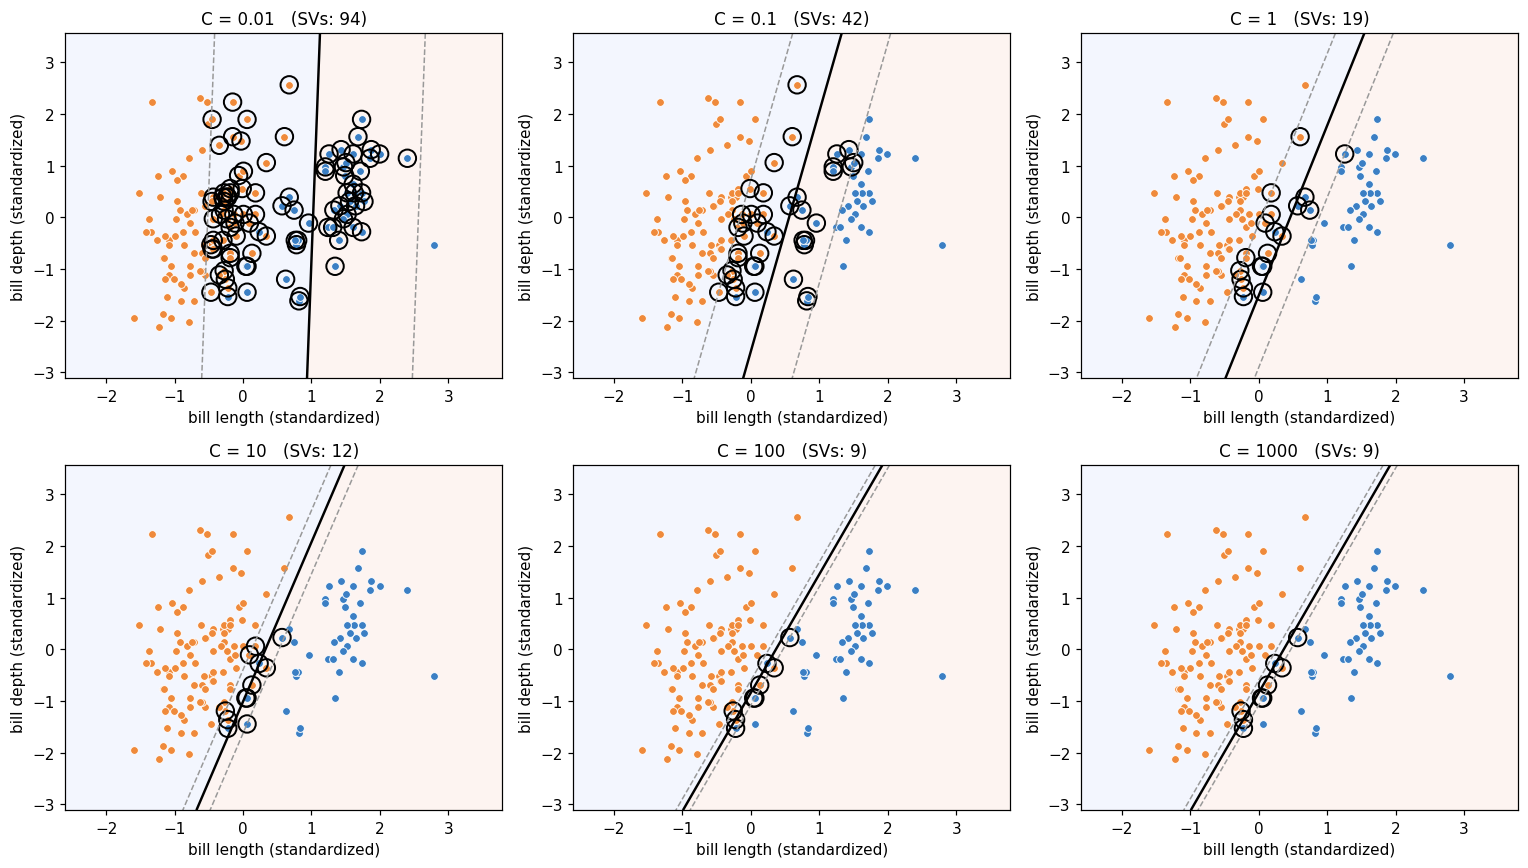

,C,train_acc,test_acc,n_support
0,0.01,0.901961,0.818182,94
1,0.10,0.960784,0.969697,42
2,1.00,0.973856,0.969697,19
3,10.00,0.973856,0.984848,12
4,100.00,0.973856,0.969697,9
5,1000.00,0.973856,0.969697,9


In [9]:
C_VALUES = [0.01, 0.1, 1, 10, 100, 1000]
results = []

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for C, ax in zip(C_VALUES, axes.ravel()):
    # TODO: fit a linear SVM with this C on the scaled training data
    model = SVC(kernel="linear", C=C).fit(X_train_s, y_train)
    # TODO: compute train accuracy, test accuracy, and number of support vectors
    tr = model.score(X_train_s, y_train)
    te = model.score(X_test_s, y_test)
    nsv = model.support_vectors_.shape[0]
    results.append({"C": C, "train_acc": tr, "test_acc": te, "n_support": nsv})
    plot_svm_boundary(model, X_train_s, y_train,
                      ax=ax, title=f"C = {C}   (SVs: {nsv})")
plt.tight_layout(); plt.show()

results = pd.DataFrame(results)
results

---
## Part 6 — The bias–variance curve

Turn your `results` table into a picture. Fill in the TODO to plot, against `C` on a **log scale**:
- training accuracy and test accuracy (left axis), and
- the number of support vectors (a second plot).

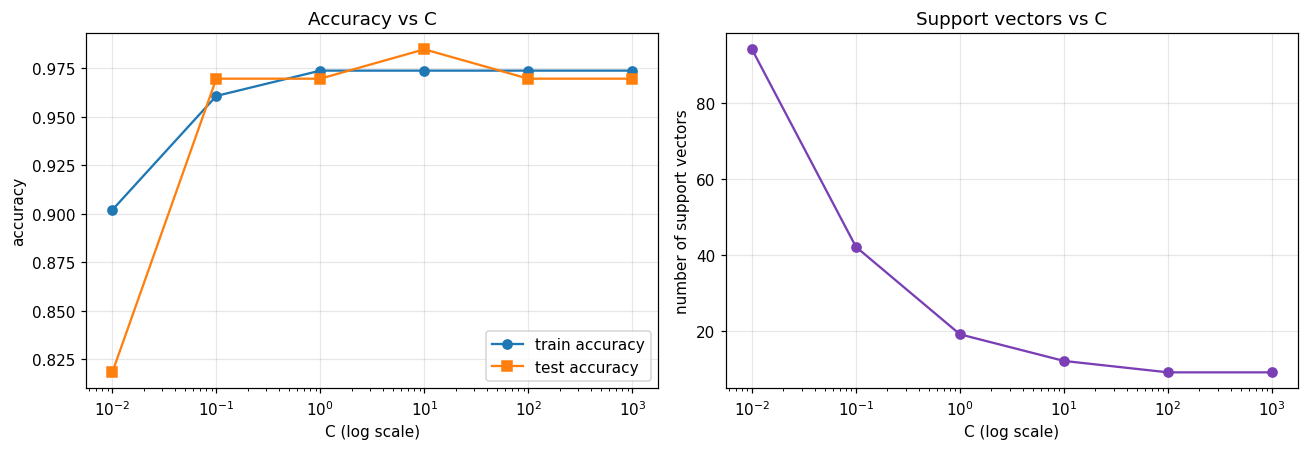

Best test accuracy at C = 10.0  -> test acc = 0.985


In [10]:
# TODO: make two plots from the `results` DataFrame (use a LOG x-axis for C):
#   Left  : train_acc and test_acc vs C
#   Right : n_support vs C
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

# ... your plotting code here ...
ax1.semilogx(results.C, results.train_acc, "o-", label="train accuracy")
ax1.semilogx(results.C, results.test_acc, "s-", label="test accuracy")
ax1.set_xlabel("C (log scale)"); ax1.set_ylabel("accuracy")
ax1.set_title("Accuracy vs C"); ax1.legend(); ax1.grid(alpha=0.3)

ax2.semilogx(results.C, results.n_support, "o-", color="#7a3fb5")
ax2.set_xlabel("C (log scale)"); ax2.set_ylabel("number of support vectors")
ax2.set_title("Support vectors vs C"); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

# TODO: print the C with the highest test accuracy
best = results.loc[results.test_acc.idxmax()]
print("Best test accuracy at C =", best.C, " -> test acc =", round(best.test_acc, 3))

**Q4 (written).** Describe what happens to the **margin width** and the **number of support
vectors** as `C` increases from 0.01 to 1000. Does this match the lecture's claim that *large C =
narrow, strict street* and *small C = wide, lenient street*?

*Your answer:* ✍️As C increases from 0.01 to 1000, the margin gets **narrower** (street width 2/‖w‖ shrinks from about 3.08 to about 0.19 in standardized units) and the number of support vectors **drops** from 94 to 9 (94 → 42 → 19 → 12 → 9 → 9). Yes, this matches the lecture: small C tolerates many margin violations, giving a wide, lenient street with many points inside it, so many support vectors; large C penalizes violations heavily, giving a narrow, strict street fit tightly around the data with few support vectors. Beyond C of about 100 nothing changes because the data is already as well separated as a line allows.

**Q5 (written).** Which end of the `C` range is **underfitting** (high bias) and which is
**overfitting** (high variance)? Point to the evidence in your accuracy curve (the gap between
train and test).

*Your answer:* ✍️**Small C (0.01)** is underfitting / high bias: the margin is so wide and lenient that the boundary misclassifies many points, with train accuracy of only 0.90 and test accuracy 0.82, both low. **Large C (100–1000)** is the high-variance end: the margin is narrow and the boundary hinges on just 9 points. Here the overfitting is only mild, since train accuracy is 0.974 and test accuracy 0.970 with almost no gap, because this pair is nearly linearly separable and a linear model has limited capacity. The best test accuracy (0.985) is at the moderate C = 10, between the two extremes.

**Q6 (written).** A classmate says "just always use the biggest `C` so the training accuracy is
highest." Explain why that is a bad idea.

*Your answer:* ✍️Higher training accuracy is not the goal; performance on new data is. A very large C fits training noise and outliers, so the boundary becomes sensitive to a few points (high variance) and the narrow margin makes the classifier less robust. In our results, raising C from 1 to 1000 did not raise training accuracy beyond 0.974, and test accuracy did not improve either (it peaked at C = 10). On harder or noisier data a huge C would overfit and test accuracy would drop. C should be chosen by validation or cross-validation, not by training accuracy.

---
## Part 7 (stretch 🌟) — A curved boundary with the RBF kernel

A straight line is not always enough. The **RBF kernel** lets the boundary bend. It adds a second
knob, `gamma`, that controls how wiggly the boundary can get. Fill in the TODO to train RBF SVMs
for a few `(C, gamma)` pairs and plot them.

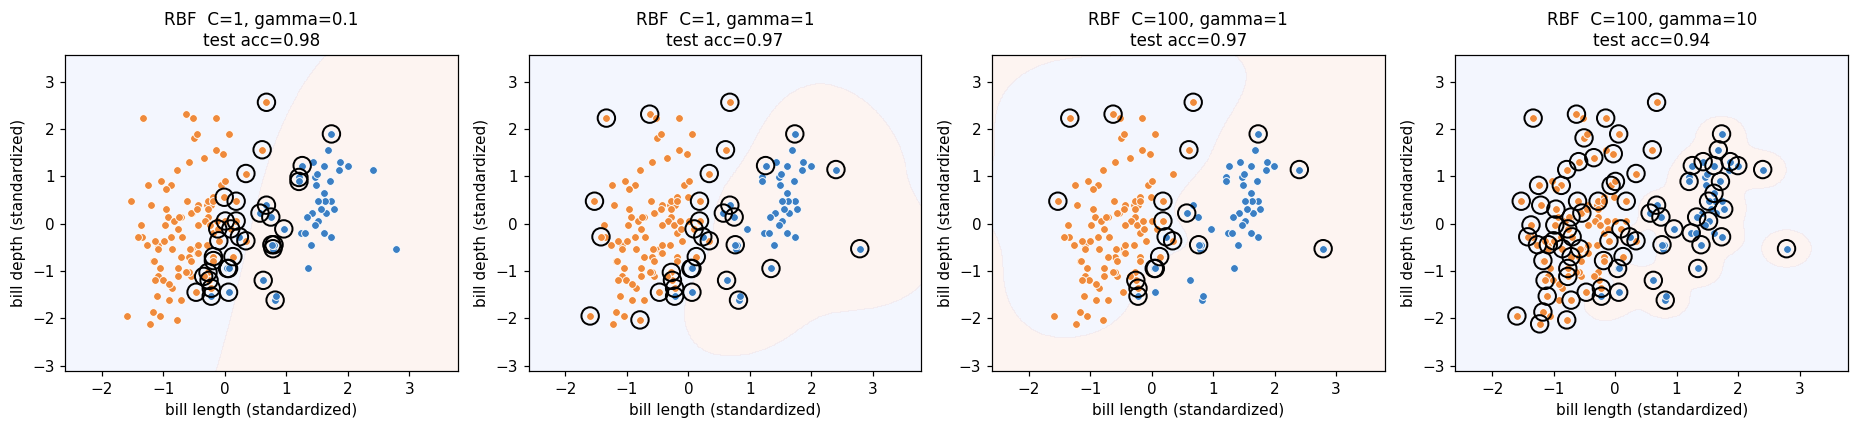

In [11]:
combos = [(1, 0.1), (1, 1), (100, 1), (100, 10)]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for (C, g), ax in zip(combos, axes):
    # TODO: fit an RBF-kernel SVM with this C and gamma, then plot it
    model = SVC(kernel="rbf", C=C, gamma=g).fit(X_train_s, y_train)
    plot_svm_boundary(model, X_train_s, y_train, ax=ax, show_margins=False,
                      title=f"RBF  C={C}, gamma={g}\ntest acc={model.score(X_test_s, y_test):.2f}")
plt.tight_layout(); plt.show()

**Q7 (written, stretch).** What happens to the boundary when **both** `C` and `gamma` are
large? Why is that dangerous?

*Your answer:* ✍️ When both C and gamma are large the boundary becomes very wiggly and forms small islands around individual training points: large gamma makes each point's influence very local, and large C forces the model to classify every training point correctly. In our run, C = 100 and gamma = 10 reached 1.00 train accuracy but only 0.94 test accuracy, with 83 support vectors. That is dangerous because it is overfitting (memorizing noise), so the model looks perfect on the training data but generalizes worse to new data.

---
## Part 8 (stretch 🌟) — Let the computer pick `C` with cross-validation

Instead of eyeballing, use `GridSearchCV` to search for the best `(C, gamma)` by 5-fold
cross-validation. Fill in the TODO.

In [12]:
# TODO: set up a GridSearchCV over C and gamma for an RBF SVC, cv=5, and fit it.
param_grid = {"C": [0.1, 1, 10, 100, 1000],
              "gamma": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=5)
grid.fit(X_train_s, y_train)

print("Best params:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 3))
print("Test accuracy of best model:", round(grid.score(X_test_s, y_test), 3))

Best params: {'C': 100, 'gamma': 0.1}
Best CV accuracy: 0.981
Test accuracy of best model: 0.985


---
## ✅ Submission checklist
- [ ] The notebook runs top-to-bottom with **no errors** (Kernel ▸ Restart & Run All).
- [ ] Every `# TODO` is completed.
- [ ] Written answers **Q1–Q6** are filled in (Q7 if attempted).
- [ ] `penguins.csv` is submitted alongside the notebook (or note that it's provided).
- [ ] Rename the file to `svm_<yourname>.ipynb` before submitting.

## Grading rubric (100 pts)
| Part | What we check | Pts |
|---|---|---:|
| Part 2–3 | Correct `X`/`y`, train/test split, and **scaling done right** (fit on train only) | 20 |
| Part 4 | Linear SVM trained; accuracy & support vectors reported; boundary plotted | 15 |
| Part 5 | **C-sweep** correct: models trained, metrics recorded, all six boundaries plotted | 25 |
| Part 6 | Bias–variance curves correct; best `C` identified | 15 |
| Q1–Q6 | Clear, correct written reasoning linking results to margin / support vectors / bias–variance | 20 |
| Stretch | Parts 7–8 attempted and sensible (bonus) | +5 |
| | **Total** | **100** |

> **Hint if you're stuck:** every modelling step is a one-liner with scikit-learn —
> `SVC(kernel=..., C=...).fit(X, y)`, `.score(X, y)`, `.support_vectors_`,
> `.decision_function(X)`. The hard part is *interpreting* what you see, not the code.
